# Traffic Collision Data Analysis

# Objective

In this case study, you will be working on California Traffic Collision Data Analysis using Apache Spark, a powerful distributed computing framework designed for big data processing. This assignment aims to provide hands-on experience in analyzing large-scale traffic collision datasets using PySpark and AWS services. You will apply data analytics techniques to clean, transform, and explore crash data, drawing meaningful insights to support traffic safety and urban planning. Beyond understanding how big data tools optimize performance on a single machine and across clusters, you will develop a structured approach to analyzing crash trends, identifying high-risk locations, and evaluating contributing factors to traffic incidents. Additionally, you will utilize AWS S3 to store the processed data efficiently after the ETL process, enabling scalable storage and easy retrieval for further analysis.


# Business Value:

Traffic collisions pose significant risks to public safety, requiring continuous monitoring and analysis to enhance road safety measures. Government agencies, city planners, and policymakers must leverage data-driven insights to improve infrastructure, optimize traffic management, and implement preventive measures.

In this assignment, you will analyze California traffic collision data to uncover patterns related to accident severity, location-based risks, and key contributing factors. With Apache Spark's ability to handle large datasets efficiently and AWS S3's scalable storage, transportation authorities can process vast amounts of crash data in real time, enabling faster and more informed decision-making.

As an analyst examining traffic safety trends, your task is to analyze historical crash data to derive actionable insights that can drive policy improvements and safety interventions. Your analysis will help identify high-risk areas, categorize accidents by severity and contributing factors, and store the processed data in an AWS S3 bucket for scalable and long-term storage.

By leveraging big data analytics and cloud-based storage, urban planners and traffic authorities can enhance road safety strategies, reduce accident rates, and improve public transportation planning.


# Dataset Overview

The dataset used in this analysis consists of California traffic collision data obtained from the Statewide Integrated Traffic Records System (SWITRS). It includes detailed records of traffic incidents across California, covering various attributes such as location, severity, involved parties, and contributing factors. The dataset has been preprocessed and transformed using PySpark to facilitate large-scale analysis. By leveraging Apache Spark, we ensure efficient data handling, enabling deeper insights into traffic patterns, accident trends, and potential safety improvements.

The dataset is a .sqlite file contains detailed information about traffic collisions across California and is structured into four primary tables:
- `collisions` table contains information about the collision, where it happened, what vehicles were involved.

- `parties` table contains information about the groups people involved in the collision including age, sex, and sobriety.

- `victims` table contains information about the injuries of specific people involved in the collision.

- `locations` table contains information about the geographical location and details of road intersections.

# Assignment Tasks

<ol>
    <li>
        <strong>Data Preparation</strong></br>
        The dataset consists of structured tables containing traffic collision data. Before conducting any analysis, it is essential to ensure that the data is properly formatted and structured for efficient processing.</br>
        Check for data consistency and ensure all columns are correctly formatted.</br>
        Apply sampling techniques if needed to extract a representative subset for analysis.</br>
        Structure and prepare the data for further processing and analysis.</br>
    </br>
    <li>
        <strong>Data Cleaning</strong></br>
            2.1 <strong>Fixing Columns:</strong> Ensure all columns are properly named and formatted.</br>
            2.2 <strong>Handling Missing Values:</strong> Decide on an approach to handle missing data (e.g., imputation or removal). Mention the approach in your report.</br>
            2.3 <strong>Handling Outliers:</strong> Identify outliers in the dataset and explain why they are considered outliers. It is not necessary to remove them for this task, but mention your approach for handling them.</br>
    </br>
    <li>
        <strong>Exploratory Data Analysis</strong></br>
        Finding Patterns and analyze the dataset and find patterns based on the following points:
                <ul>
                3.1 Classify variables into categorical and numerical types.</br>
                3.2 Analyze the distribution of collision severity.</br>
                3.3 Examine weather conditions during collisions.</br>
                3.4 Analyze the distribution of victim ages.</br>
                3.5 Study the relationship between collision severity and the number of victims.</br>
                3.6 Analyze the correlation between weather conditions and collision severity.</br>
                3.7 Visualize the impact of lighting conditions on collision severity.</br>
                3.8 Extract and analyze weekday-wise collision trends.</br>
                3.9 Assess the number of collisions occurring on different days of the week.</br>
                3.10 Study spatial distribution of collisions by county.</br>
                3.11 Generate a scatter plot to analyze collision locations geographically.</br>
                3.12 Extract and analyze collision trends over time, including yearly, monthly, and hourly trends.</br>
</ul>
</br>
<li>
<strong>ETL Querying</strong><br>
Write PySpark SQL queries for the following:</br>
<ol>
    4.1. Identify the top 5 counties with the highest number of collisions.</br>
    4.2. Identify the month with the highest number of collisions.</br>
    4.3. Determine the most common weather condition during collisions.</br>
    4.4. Calculate the percentage of collisions that resulted in fatalities.</br>
    4.5. Find the most dangerous time of day for collisions.</br>
    4.6. Identify the top 5 road surface conditions with the highest collision frequency.</br>
    4.7. Analyze lighting conditions that contribute to the highest number of collisions.</br>
</ol>
</br>
<li>
<strong>Conclusion</strong></br>
Provide final insights and recommendations based on the analysis:
    <ul>
        5.1 Recommendations to improve road safety by identifying high-risk locations and peak accident times for infrastructure improvements.</br>
        5.2 Suggestions to optimize traffic management by analyzing trends in collision severity, weather conditions, and lighting to improve road design and traffic signal timing.</br>
        5.3 Propose data-driven policy changes to enhance pedestrian and cyclist safety based on collision trends involving vulnerable road users.</br>
        5.4 Identify potential high-risk zones for proactive intervention by examining geographic collision density and historical accident data.</br>
        5.5 Assess the impact of environmental factors such as weather, road surface conditions, and lighting on accident frequency and severity.</br>
        5.6 Develop predictive models to anticipate collision hotspots and support proactive safety measures.</br>
        </ul>
        Conclude the analysis by summarizing key findings and business implications.</br>
        Explain the results of univariate, segmented univariate, and bivariate analyses in real-world traffic safety and policy terms.</br>
        Include visualizations and summarize the most important results in the report. Insights should explain why each variable is important and how they can influence traffic safety policies and urban planning.</br>
        </ul>
        </br>
    <li>
    <strong>Visualization Integration [Optional]</strong>
    <p>Enhance the project by incorporating a visualization component that connects the processed data stored in an S3 bucket to a business intelligence tool such as Tableau or Power BI. This involves setting up the connection between the S3 bucket and the chosen visualization tool, importing the processed dataset for analysis and visualization, creating interactive dashboards to explore key trends and insights and ensuring data updates are reflected dynamically in the visualization tool.<br>
</br>
</ol>

In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

Install Required Libraries

In [2]:
## Install the required libraries
# !pip install --quiet pyspark==3.5.4 pandas==2.2.2

In [3]:
# Import the necessary libraries
import sqlite3
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col,
    sum,
    to_date,
    when,
    year,
    month,
    to_timestamp,
    hour,
    date_format
)
from pyspark.sql.types import DateType
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns


from pyspark.sql.types import StringType
from pyspark.ml.feature import StringIndexer

import calendar



#**1. Data Preparation** <font color = red>[5 marks]</font> <br>

The dataset consists of structured tables containing traffic collision data.

Before conducting any analysis, it is essential to ensure that the data is properly formatted and structured for efficient processing.

Check for data consistency and ensure all columns are correctly formatted.

In [4]:
# Write code to load the data and check the schema
spark = SparkSession.builder.appName("collision-assesment").getOrCreate()

dfs = {}
for file in Path("./Crash_Data_Analysis_Dataset/").glob("sample_*.csv"):
    file_key = file.stem.removeprefix("sample_")
    dfs[file_key] = (
        spark.read
        .option("header", True)
        .option("inferSchema", True)
        .csv(str(file))
    )
dfs.keys()

dict_keys(['collisions', 'victims', 'case_ids', 'parties'])

#**2. Data Cleaning** <font color = red>[20 marks]</font> <br>


In [5]:
#Display Schema & Sample Data


In [6]:
for name, df in dfs.items():
    print(f"Column names of {name}:")
    print(df.columns)
    print('==================')

Column names of collisions:
['case_id', 'jurisdiction', 'officer_id', 'reporting_district', 'chp_shift', 'population', 'county_city_location', 'county_location', 'special_condition', 'beat_type', 'chp_beat_type', 'chp_beat_class', 'beat_number', 'primary_road', 'secondary_road', 'distance', 'direction', 'intersection', 'weather_1', 'state_highway_indicator', 'caltrans_county', 'caltrans_district', 'state_route', 'postmile', 'location_type', 'side_of_highway', 'tow_away', 'collision_severity', 'killed_victims', 'injured_victims', 'party_count', 'primary_collision_factor', 'pcf_violation_category', 'pcf_violation', 'pcf_violation_subsection', 'hit_and_run', 'type_of_collision', 'motor_vehicle_involved_with', 'pedestrian_action', 'road_surface', 'road_condition_1', 'lighting', 'control_device', 'chp_road_type', 'pedestrian_collision', 'bicycle_collision', 'motorcycle_collision', 'truck_collision', 'not_private_property', 'statewide_vehicle_type_at_fault', 'chp_vehicle_type_at_fault', 'sev

In [7]:
dfs["collisions"].show(1, vertical=True)

-RECORD 0-----------------------------------------------
 case_id                         | 8000993.0            
 jurisdiction                    | 1942.0               
 officer_id                      | 39335                
 reporting_district              | 1676                 
 chp_shift                       | not chp              
 population                      | >250000              
 county_city_location            | 1942                 
 county_location                 | los angeles          
 special_condition               | 0.0                  
 beat_type                       | not chp              
 chp_beat_type                   | not chp              
 chp_beat_class                  | not chp              
 beat_number                     | 9TL56                
 primary_road                    | NETTLETON ST         
 secondary_road                  | GLENOAKS             
 distance                        | 300.0                
 direction                     

In [8]:
print(dfs["victims"].show(1, vertical=True))

-RECORD 0-----------------------------------------
 id                        | 2166324              
 case_id                   | 6324923.0            
 party_number              | 1                    
 victim_role               | driver               
 victim_sex                | male                 
 victim_age                | 62.0                 
 victim_degree_of_injury   | complaint of pain    
 victim_seating_position   | driver               
 victim_safety_equipment_1 | air bag not deployed 
 victim_safety_equipment_2 | lap/shoulder harn... 
 victim_ejected            | not ejected          
only showing top 1 row

None


In [9]:
print(dfs["parties"].show(1, vertical=True))

-RECORD 0--------------------------------------------
 id                           | 1292305              
 case_id                      | 4843348.0            
 party_number                 | 1                    
 party_type                   | driver               
 at_fault                     | 1                    
 party_sex                    | male                 
 party_age                    | 28.0                 
 party_sobriety               | had not been drin... 
 direction_of_travel          | south                
 party_safety_equipment_1     | lap/shoulder harn... 
 party_safety_equipment_2     | NULL                 
 financial_responsibility     | no proof of insur... 
 cellphone_in_use             | NULL                 
 cellphone_use_type           | NULL                 
 other_associate_factor_1     | inattention          
 party_number_killed          | 0                    
 party_number_injured         | 0                    
 movement_preceding_collisio

In [10]:
print(dfs["case_ids"].show(1, vertical=True))

-RECORD 0--------------
 case_id | 9.0017156E7 
 db_year | 2021        
only showing top 1 row

None


##**2.1 Missing Values** <font color = red>[10 marks]</font> <br>


In [11]:
#Check for Missing Values
def get_missing_values(df):
    total_rows = df.count()

    missing_df = (
        df.select([
            sum(when(col(c).isNull(), 1).otherwise(0)).alias(c)
            for c in df.columns
        ])
        .toPandas()
        .T
        .reset_index()
    )
    
    missing_df.columns = ["Column", "missing values"]
    
    missing_df['missing percent'] = (
        missing_df['missing values'] / total_rows * 100
    ).round(2)
    
    missing_df = (
        missing_df.sort_values(
            by="missing percent",
            ascending=False
        )
        .reset_index(drop=True)
    )


    missing_df = (
        missing_df[missing_df["missing values"] > 0]
        .sort_values('missing percent', ascending = False)
        .reset_index(drop= True)
    )
    return missing_df
    

In [12]:
# Work on collision data
collision_missing = get_missing_values(dfs["collisions"])
display(collision_missing)

,Column,missing values,missing percent
0,side_of_highway,682077,72.89
1,location_type,682075,72.89
2,caltrans_county,682075,72.89
3,longitude,669049,71.50
4,latitude,669049,71.50
5,postmile,648728,69.32
6,state_route,648728,69.32
7,caltrans_district,648728,69.32
8,pcf_violation_subsection,601427,64.27
9,reporting_district,552653,59.06


In [13]:
# Work on victims data
collision_missing = get_missing_values(dfs["victims"])
display(collision_missing)

,Column,missing values,missing percent
0,victim_safety_equipment_2,310220,32.18
1,victim_safety_equipment_1,55215,5.73
2,victim_age,32145,3.33
3,victim_sex,24041,2.49
4,victim_ejected,4272,0.44
5,victim_seating_position,1913,0.20
6,victim_role,1,0.00


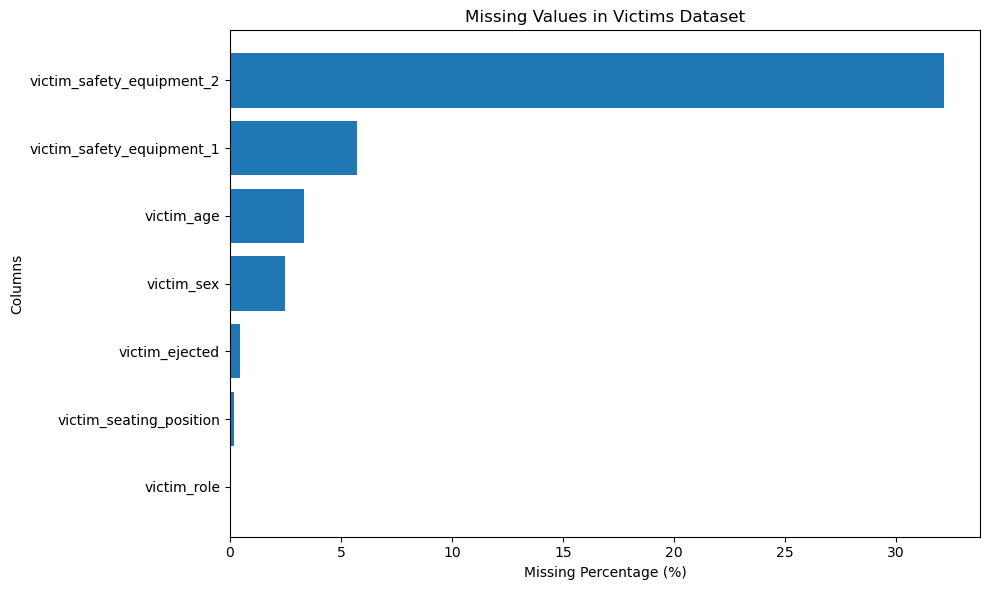

In [14]:
# Sort from highest to lowest missing percentage
plot_df = collision_missing.sort_values(
    by="missing percent",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Column"],
    plot_df["missing percent"]
)

plt.xlabel("Missing Percentage (%)")
plt.ylabel("Columns")
plt.title("Missing Values in Victims Dataset")

plt.tight_layout()
plt.show()

In [15]:
# Work on parties data
collision_missing = get_missing_values(dfs["parties"])
display(collision_missing)

,Column,missing values,missing percent
0,chp_vehicle_type_towed,909543,48.72
1,party_safety_equipment_2,699581,37.47
2,cellphone_in_use,568197,30.44
3,party_race,436844,23.40
4,cellphone_use_type,432264,23.15
5,chp_vehicle_type_towing,401142,21.49
6,party_safety_equipment_1,314883,16.87
7,party_age,290783,15.58
8,party_sex,249269,13.35
9,statewide_vehicle_type,210693,11.29


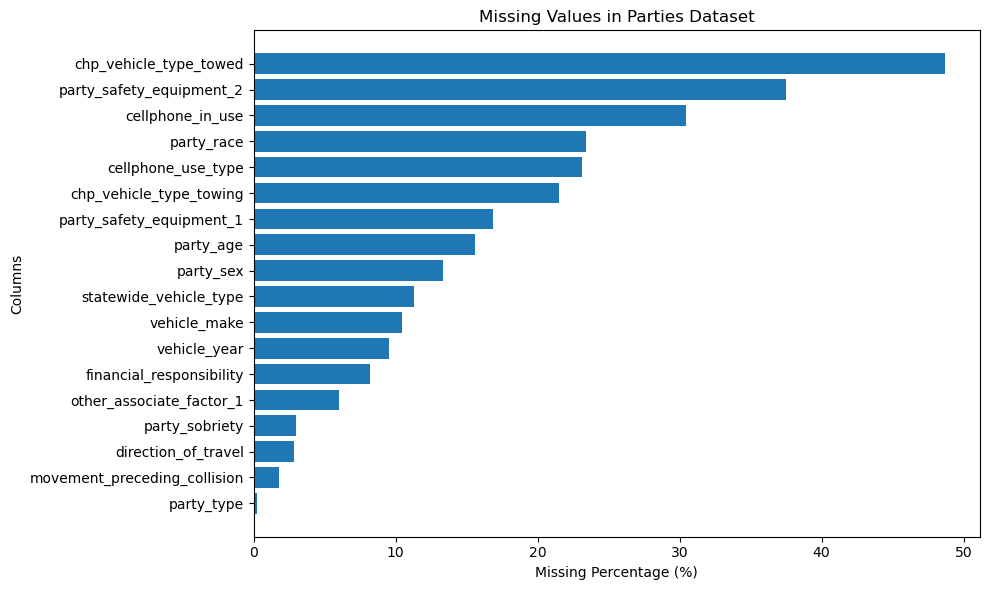

In [16]:
# Sort from highest to lowest missing percentage
plot_df = collision_missing.sort_values(
    by="missing percent",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Column"],
    plot_df["missing percent"]
)

plt.xlabel("Missing Percentage (%)")
plt.ylabel("Columns")
plt.title("Missing Values in Parties Dataset")

plt.tight_layout()
plt.show()

In [17]:
# Work on case_ids data
collision_missing = get_missing_values(dfs["case_ids"])
display(collision_missing)

,Column,missing values,missing percent


In [18]:
#Drop Sparse Columns
# No column was removed as each column hold some value

In [19]:
dfs['collisions'].select('collision_time').show()

+-------------------+
|     collision_time|
+-------------------+
|2026-07-13 16:30:00|
|2026-07-13 18:24:00|
|2026-07-13 18:15:00|
|2026-07-13 21:50:00|
|2026-07-13 17:56:00|
|2026-07-13 06:05:00|
|2026-07-13 08:09:00|
|2026-07-13 11:45:00|
|2026-07-13 11:20:00|
|2026-07-13 14:05:00|
|2026-07-13 14:27:00|
|2026-07-13 08:25:00|
|2026-07-13 15:30:00|
|2026-07-13 12:14:00|
|2026-07-13 08:35:00|
|2026-07-13 15:25:00|
|2026-07-13 17:30:00|
|2026-07-13 06:46:00|
|2026-07-13 23:30:00|
|2026-07-13 05:10:00|
+-------------------+
only showing top 20 rows



In [20]:
#Convert Data Types
 # collision date columns 'collision_date', 'collision_time', 'process_date'
dfs['collisions'] = (
    dfs['collisions']
    .withColumn(
        'collision_date',
        to_date(col('collision_date'), 'yyyy-MM-dd')
    )
    .withColumn(
        'collision_time',
        to_date(col('collision_time'), 'yyyy-MM-dd')
    )
    .withColumn(
        'process_date',
        to_date(col('process_date'), 'yyyy-MM-dd')
    )
)
dfs['collisions'].select(
    'collision_date',
    'collision_time',
    'process_date'
).printSchema()

root
 |-- collision_date: date (nullable = true)
 |-- collision_time: date (nullable = true)
 |-- process_date: date (nullable = true)



In [21]:
#Convert Data Types
 # collision parties 'vehicle_year'
dfs['parties'] = (
    dfs['parties']
    .withColumn(
        'vehicle_year',
        to_date(col('vehicle_year'), 'yyyy-MM-dd')
    )
)
dfs['parties'].select(
    'vehicle_year'
).printSchema()

root
 |-- vehicle_year: date (nullable = true)



In [22]:
#Convert Data Types
 # collision case_ids 'db_year'
dfs['case_ids'] = (
    dfs['case_ids']
    .withColumn(
        'db_year',
        to_date(col('db_year'), 'yyyy-MM-dd')
    )
)
dfs['case_ids'].select(
    'db_year'
).printSchema()

root
 |-- db_year: date (nullable = true)



In [23]:
#Handle Missing Values

categorical_fill = {
    "weather_1": "Unknown",
    "road_surface": "Unknown",
    "road_condition_1": "Unknown",
    "lighting": "Unknown",
    "control_device": "Unknown",
    "type_of_collision": "Unknown",
    "motor_vehicle_involved_with": "Unknown",
    "primary_collision_factor": "Unknown",
    "pcf_violation_category": "Unknown",
    "pcf_violation": "Unknown",
    "special_condition": "Unknown"
}

dfs["collisions"] = dfs["collisions"].fillna(categorical_fill)

In [24]:
numeric_fill = {
    "killed_victims": 0,
    "injured_victims": 0
}

dfs["collisions"] = dfs["collisions"].fillna(numeric_fill)

In [25]:
victim_fill = {
    "victim_sex": "Unknown"
}

dfs["victims"] = dfs["victims"].fillna(victim_fill)

##**2.2 Fixing Columns** <font color = red>[5 marks]</font> <br>


In [26]:
#Remove Duplicates
for name, df in dfs.items():
    total_rows = df.count()
    unique_rows = df.dropDuplicates().count()

    print(f"{name}")
    print(f"Total Rows      : {total_rows}")
    print(f"Duplicate Rows  : {total_rows - unique_rows}")
    print("-" * 50)

collisions
Total Rows      : 935791
Duplicate Rows  : 0
--------------------------------------------------
victims
Total Rows      : 963933
Duplicate Rows  : 0
--------------------------------------------------
case_ids
Total Rows      : 942433
Duplicate Rows  : 35
--------------------------------------------------
parties
Total Rows      : 1866917
Duplicate Rows  : 0
--------------------------------------------------


In [27]:
dfs["case_ids"] = dfs["case_ids"].dropDuplicates()

In [28]:
#Detect Outliers using IQR

# List of numerical columns to check for outliers

collision_cols = [
    "distance",
    "party_count",
    "killed_victims",
    "injured_victims",
    "severe_injury_count",
    "other_visible_injury_count",
    "complaint_of_pain_injury_count"
]

victim_cols = [
    "victim_age"
]

party_cols = [
    "party_age",
    "vehicle_year",
    "party_number_killed",
    "party_number_injured"
]



In [29]:
dfs["victims"].select("victim_age").printSchema()

root
 |-- victim_age: double (nullable = true)



##**2.3 Outlier Analysis** <font color = red>[5 marks]</font> <br>


In [30]:
def detect_outliers_iqr(df, column):

    # Remove null values
    clean_df = df.filter(col(column).isNotNull())

    # Handle DateType columns
    if isinstance(clean_df.schema[column].dataType, DateType):
        clean_df = clean_df.withColumn(
            "__value__",
            year(col(column))
        )
        target_col = "__value__"
    else:
        target_col = column

    # Calculate quartiles
    quantiles = clean_df.approxQuantile(
        target_col,
        [0.25, 0.75],
        0.01
    )

    if len(quantiles) < 2:
        print(f"Skipping '{column}' (unable to compute quartiles)")
        return None

    q1, q3 = quantiles

    # Calculate IQR
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Find outliers
    outlier_df = clean_df.filter(
        (col(target_col) < lower_bound) |
        (col(target_col) > upper_bound)
    )

    return {
        "Column": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_df.count()
    }

In [31]:
for column in collision_cols:
    result = detect_outliers_iqr(dfs["collisions"], column)

    if result:
        print(result)

{'Column': 'distance', 'Q1': 2.0, 'Q3': 455.0, 'IQR': 453.0, 'Lower Bound': -677.5, 'Upper Bound': 1134.5, 'Outlier Count': 108429}
{'Column': 'party_count', 'Q1': 2.0, 'Q3': 2.0, 'IQR': 0.0, 'Lower Bound': 2.0, 'Upper Bound': 2.0, 'Outlier Count': 298314}
{'Column': 'killed_victims', 'Q1': 0.0, 'Q3': 0.0, 'IQR': 0.0, 'Lower Bound': 0.0, 'Upper Bound': 0.0, 'Outlier Count': 0}
{'Column': 'injured_victims', 'Q1': 0.0, 'Q3': 1.0, 'IQR': 1.0, 'Lower Bound': -1.5, 'Upper Bound': 2.5, 'Outlier Count': 33313}
{'Column': 'severe_injury_count', 'Q1': 0.0, 'Q3': 0.0, 'IQR': 0.0, 'Lower Bound': 0.0, 'Upper Bound': 0.0, 'Outlier Count': 22138}
{'Column': 'other_visible_injury_count', 'Q1': 0.0, 'Q3': 0.0, 'IQR': 0.0, 'Lower Bound': 0.0, 'Upper Bound': 0.0, 'Outlier Count': 120687}
{'Column': 'complaint_of_pain_injury_count', 'Q1': 0.0, 'Q3': 1.0, 'IQR': 1.0, 'Lower Bound': -1.5, 'Upper Bound': 2.5, 'Outlier Count': 19718}


In [32]:
dfs["collisions"] \
    .select("distance") \
    .distinct() \
    .orderBy(col("distance").desc()) \
    .show(20, truncate=False)

+---------+
|distance |
+---------+
|8363520.0|
|6209280.0|
|3263040.0|
|2845920.0|
|2581920.0|
|2455200.0|
|1584000.0|
|1203840.0|
|1056000.0|
|879120.0 |
|792000.0 |
|776160.0 |
|601920.0 |
|543840.0 |
|533280.0 |
|528000.0 |
|522720.0 |
|485760.0 |
|475200.0 |
|396000.0 |
+---------+
only showing top 20 rows



In [33]:
dfs["collisions"] = dfs["collisions"].filter(
    col("distance") <= 10000
)

In [34]:
for column in collision_cols:
    print(f"\n{'=' * 60}")
    print(f"Column: {column}")

    dfs["collisions"] \
        .select(column) \
        .orderBy(col(column).desc()) \
        .show(20, truncate=False)


Column: distance
+--------+
|distance|
+--------+
|10000.0 |
|10000.0 |
|10000.0 |
|10000.0 |
|10000.0 |
|10000.0 |
|10000.0 |
|10000.0 |
|9997.0  |
|9979.0  |
|9979.0  |
|9979.0  |
|9979.0  |
|9979.0  |
|9950.0  |
|9926.0  |
|9926.0  |
|9926.0  |
|9926.0  |
|9900.0  |
+--------+
only showing top 20 rows


Column: party_count
+-----------+
|party_count|
+-----------+
|20.0       |
|19.0       |
|16.0       |
|14.0       |
|14.0       |
|13.0       |
|13.0       |
|13.0       |
|13.0       |
|12.0       |
|12.0       |
|12.0       |
|11.0       |
|11.0       |
|11.0       |
|11.0       |
|11.0       |
|11.0       |
|11.0       |
|10.0       |
+-----------+
only showing top 20 rows


Column: killed_victims
+--------------+
|killed_victims|
+--------------+
|0.0           |
|0.0           |
|0.0           |
|0.0           |
|0.0           |
|0.0           |
|0.0           |
|0.0           |
|0.0           |
|0.0           |
|0.0           |
|0.0           |
|0.0           |
|0.0         

In [35]:
for column in victim_cols:
    result = detect_outliers_iqr(dfs["victims"], column)

    if result:
        print(result)

{'Column': 'victim_age', 'Q1': 17.0, 'Q3': 44.0, 'IQR': 27.0, 'Lower Bound': -23.5, 'Upper Bound': 84.5, 'Outlier Count': 5651}


In [37]:
dfs["victims"] \
    .select("victim_age") \
    .orderBy(col("victim_age").desc()) \
    .show(30, truncate=False)

+----------+
|victim_age|
+----------+
|999.0     |
|999.0     |
|999.0     |
|999.0     |
|999.0     |
|999.0     |
|999.0     |
|999.0     |
|999.0     |
|999.0     |
|999.0     |
|999.0     |
|999.0     |
|999.0     |
|999.0     |
|999.0     |
|999.0     |
|999.0     |
|999.0     |
|999.0     |
|125.0     |
|125.0     |
|124.0     |
|123.0     |
|123.0     |
|122.0     |
|122.0     |
|122.0     |
|122.0     |
|121.0     |
+----------+
only showing top 30 rows



In [38]:
dfs["victims"] = dfs["victims"].filter(
    col("victim_age") != 999
)

In [39]:
dfs["victims"] = dfs["victims"].filter(
    (col("victim_age") >= 0) &
    (col("victim_age") <= 120)
)

In [40]:
dfs["victims"] \
    .groupBy("victim_age") \
    .count() \
    .orderBy(col("victim_age").desc()) \
    .show(30, truncate=False)

+----------+-----+
|victim_age|count|
+----------+-----+
|120.0     |1    |
|117.0     |2    |
|115.0     |3    |
|114.0     |1    |
|113.0     |1    |
|112.0     |2    |
|111.0     |3    |
|110.0     |2    |
|109.0     |5    |
|108.0     |7    |
|107.0     |5    |
|106.0     |6    |
|105.0     |5    |
|104.0     |11   |
|103.0     |16   |
|102.0     |13   |
|101.0     |20   |
|100.0     |25   |
|99.0      |40   |
|98.0      |23   |
|97.0      |44   |
|96.0      |72   |
|95.0      |100  |
|94.0      |134  |
|93.0      |182  |
|92.0      |241  |
|91.0      |337  |
|90.0      |433  |
|89.0      |538  |
|88.0      |616  |
+----------+-----+
only showing top 30 rows



In [41]:
for column in party_cols:
    result = detect_outliers_iqr(dfs["parties"], column)

    if result:
        print(result)

{'Column': 'party_age', 'Q1': 25.0, 'Q3': 50.0, 'IQR': 25.0, 'Lower Bound': -12.5, 'Upper Bound': 87.5, 'Outlier Count': 4552}
Skipping 'vehicle_year' (unable to compute quartiles)
{'Column': 'party_number_killed', 'Q1': 0.0, 'Q3': 0.0, 'IQR': 0.0, 'Lower Bound': 0.0, 'Upper Bound': 0.0, 'Outlier Count': 6889}
{'Column': 'party_number_injured', 'Q1': 0.0, 'Q3': 0.0, 'IQR': 0.0, 'Lower Bound': 0.0, 'Upper Bound': 0.0, 'Outlier Count': 437989}


In [42]:
dfs["parties"] \
    .groupBy("party_age") \
    .count() \
    .orderBy(col("party_age").desc()) \
    .show(30, truncate=False)

+---------+-----+
|party_age|count|
+---------+-----+
|122.0    |1    |
|121.0    |3    |
|120.0    |2    |
|118.0    |3    |
|114.0    |1    |
|112.0    |1    |
|110.0    |1    |
|108.0    |1    |
|106.0    |1    |
|105.0    |6    |
|104.0    |9    |
|103.0    |15   |
|102.0    |38   |
|101.0    |35   |
|100.0    |172  |
|99.0     |148  |
|98.0     |103  |
|97.0     |105  |
|96.0     |121  |
|95.0     |139  |
|94.0     |167  |
|93.0     |243  |
|92.0     |339  |
|91.0     |452  |
|90.0     |609  |
|89.0     |816  |
|88.0     |1021 |
|87.0     |1233 |
|86.0     |1578 |
|85.0     |1809 |
+---------+-----+
only showing top 30 rows



In [43]:
# party_number_killed
dfs["parties"] \
    .groupBy("party_number_killed") \
    .count() \
    .orderBy(col("party_number_killed").desc()) \
    .show(20)

# party_number_injured
dfs["parties"] \
    .groupBy("party_number_injured") \
    .count() \
    .orderBy(col("party_number_injured").desc()) \
    .show(20)

+-------------------+-------+
|party_number_killed|  count|
+-------------------+-------+
|                  7|      1|
|                  6|      3|
|                  5|      4|
|                  4|     10|
|                  3|     59|
|                  2|    332|
|                  1|   6480|
|                  0|1860028|
+-------------------+-------+

+--------------------+-----+
|party_number_injured|count|
+--------------------+-----+
|                  42|    1|
|                  34|    1|
|                  33|    1|
|                  25|    1|
|                  24|    1|
|                  22|    2|
|                  21|    1|
|                  19|    3|
|                  16|    3|
|                  15|    2|
|                  14|    4|
|                  13|    5|
|                  12|    4|
|                  11|    9|
|                  10|   16|
|                   9|   18|
|                   8|   30|
|                   7|   82|
|                   6|  255|
|

#**3. Exploratory Data Analysis** <font color = red>[65 marks]</font> <br>


##**3.1.1. Data Preparation** <font color = red>[5 marks]</font> <br>

Q: Classify variables into categorical and numerical.

In [44]:
# Encode Categorical Variables

# String Indexing for Categorical Columns
categorical_cols = [
    field.name
    for field in dfs["collisions"].schema.fields
    if isinstance(field.dataType, StringType)
]

print(categorical_cols)

['officer_id', 'reporting_district', 'chp_shift', 'population', 'county_location', 'beat_type', 'chp_beat_type', 'chp_beat_class', 'beat_number', 'primary_road', 'secondary_road', 'direction', 'weather_1', 'caltrans_county', 'location_type', 'side_of_highway', 'collision_severity', 'primary_collision_factor', 'pcf_violation_category', 'pcf_violation_subsection', 'hit_and_run', 'type_of_collision', 'motor_vehicle_involved_with', 'pedestrian_action', 'road_surface', 'road_condition_1', 'lighting', 'control_device', 'statewide_vehicle_type_at_fault', 'chp_vehicle_type_at_fault']


In [45]:
for column in categorical_cols:
    indexer = StringIndexer(
        inputCol=column,
        outputCol=f"{column}_index",
        handleInvalid="keep"
    )

    dfs["collisions"] = indexer.fit(dfs["collisions"]).transform(dfs["collisions"])

In [46]:
dfs["collisions"].select(
    categorical_cols[:3] +
    [f"{c}_index" for c in categorical_cols[:3]]
).show(5)

+----------+------------------+--------------+----------------+------------------------+---------------+
|officer_id|reporting_district|     chp_shift|officer_id_index|reporting_district_index|chp_shift_index|
+----------+------------------+--------------+----------------+------------------------+---------------+
|     39335|              1676|       not chp|         14395.0|                  1411.0|            0.0|
|      1284|                Z2|       not chp|          4090.0|                   640.0|            0.0|
|    019223|              NULL|1400 thru 2159|          9901.0|                 15003.0|            1.0|
|     50586|              3610|       not chp|         11593.0|                    35.0|            0.0|
|    649318|              0261|       not chp|         34438.0|                  1064.0|            0.0|
+----------+------------------+--------------+----------------+------------------------+---------------+
only showing top 5 rows



In [47]:
# Reordering & Renaming Columns
dfs["collisions"] = (
    dfs["collisions"]
    .withColumnRenamed("weather_1", "weather")
    .withColumnRenamed("road_condition_1", "road_condition")
)

In [48]:
# Final cleaned data
# Final cleaned collisions dataset
cleaned_collisions = dfs["collisions"].select(
    "case_id",
    "collision_date",
    "collision_time",
    "collision_severity",
    "county_location",
    "county_city_location",
    "primary_road",
    "secondary_road",
    "weather",
    "lighting",
    "road_condition",
    "party_count",
    "killed_victims",
    "injured_victims",
    *[
        c for c in dfs["collisions"].columns
        if c not in [
            "case_id",
            "collision_date",
            "collision_time",
            "collision_severity",
            "county_location",
            "county_city_location",
            "primary_road",
            "secondary_road",
            "weather",
            "lighting",
            "road_condition",
            "party_count",
            "killed_victims",
            "injured_victims",
        ]
    ]
)

In [49]:
cleaned_victims = dfs["victims"].select(
    "case_id",
    "id",
    "party_number",
    "victim_role",
    "victim_age",
    "victim_sex",
    "victim_degree_of_injury",
    "victim_seating_position",
    "victim_safety_equipment_1",
    "victim_safety_equipment_2",
    "victim_ejected"
)

In [50]:
cleaned_parties = dfs["parties"].select(
    "case_id",
    "id",
    "party_number",
    "party_type",
    "at_fault",
    "party_age",
    "party_sex",
    "party_race",
    "party_sobriety",
    "direction_of_travel",
    "movement_preceding_collision",
    "vehicle_make",
    "vehicle_year",
    "statewide_vehicle_type",
    "chp_vehicle_type_towing",
    "chp_vehicle_type_towed",
    "party_number_killed",
    "party_number_injured",
    "financial_responsibility",
    "cellphone_in_use",
    "cellphone_use_type",
    "party_safety_equipment_1",
    "party_safety_equipment_2",
    "other_associate_factor_1"
)

In [51]:
cleaned_case_ids = dfs["case_ids"].select(
    "case_id",
    "db_year"
)

In [52]:
dfs["victims"] = cleaned_victims
dfs["parties"] = cleaned_parties
dfs["case_ids"] = cleaned_case_ids
dfs["collisions"] = cleaned_collisions

Loading the Final Cleaned Dataset into S3 Bucket

##**3.1.2. Analyze the distribution of collision severity.** <font color = red>[5 marks]</font> <br>

Q: Analyze the distribution of collision severity.

/tmp/ipykernel_53627/415035974.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 t

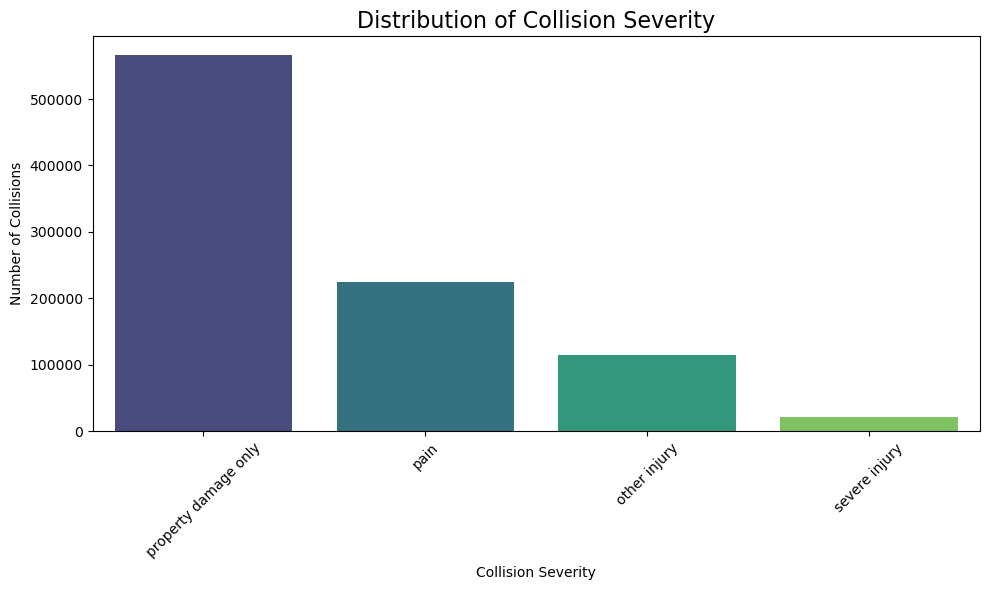

In [53]:
# Univariate Analysis

# Collision Severity Distribution
severity_df = (
    cleaned_collisions
    .groupBy("collision_severity")
    .count()
    .orderBy("count", ascending=False)
)

# Convert to Pandas
severity_pd = severity_df.toPandas()
severity_pd
# Plot

plt.figure(figsize=(10, 6))

sns.barplot(
    data=severity_pd,
    x="collision_severity",
    y="count",
    palette="viridis"
)

plt.title("Distribution of Collision Severity", fontsize=16)
plt.xlabel("Collision Severity")
plt.ylabel("Number of Collisions")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

##**3.1.3. Weather conditions during collisions.** <font color = red>[5 marks]</font> <br>

Q: Examine weather conditions during collisions.

/tmp/ipykernel_53627/422150329.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 t

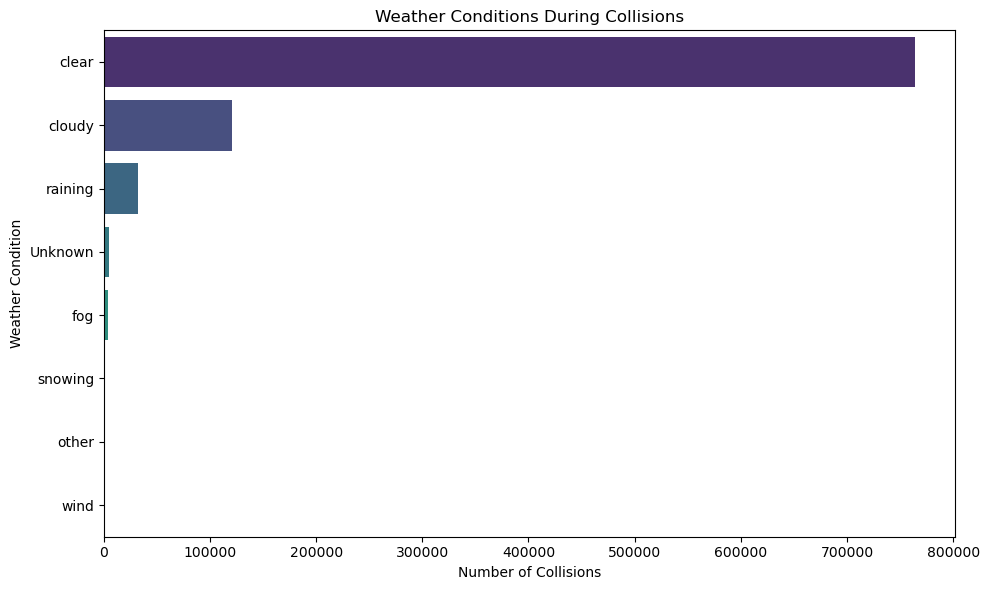

In [54]:
# Weather Conditions During Collisions
weather_df = (
    cleaned_collisions
    .groupBy("weather")
    .count()
    .orderBy("count", ascending=False)
)
# Convert to Pandas
weather_pd = weather_df.toPandas()

weather_pd
# Plot

plt.figure(figsize=(10, 6))

sns.barplot(
    data=weather_pd,
    y="weather",
    x="count",
    palette="viridis"
)

plt.title("Weather Conditions During Collisions")
plt.xlabel("Number of Collisions")
plt.ylabel("Weather Condition")

plt.tight_layout()
plt.show()

##**3.1.4. Victime Age Distribution.** <font color = red>[5 marks]</font> <br>

Q: Analyze the distribution of victim ages.

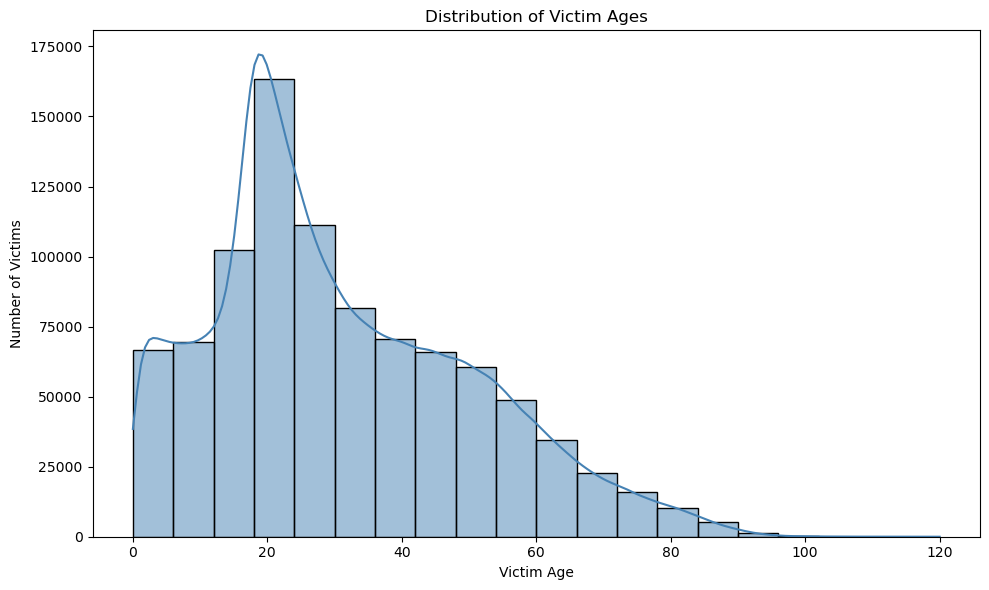

In [55]:
# Distribution of Victim Ages
victim_age_pd = (
    cleaned_victims
    .select("victim_age")
    .dropna()
    .toPandas()
)
# Convert to Pandas

# Plot
plt.figure(figsize=(10, 6))

sns.histplot(
    data=victim_age_pd,
    x="victim_age",
    bins=20,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Victim Ages")
plt.xlabel("Victim Age")
plt.ylabel("Number of Victims")

plt.tight_layout()
plt.show()

##**3.1.5. Collision Severity vs Number of Victims.** <font color = red>[5 marks]</font> <br>

Q: Study the relationship between collision severity and the number of victims.

/tmp/ipykernel_53627/1252528682.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 

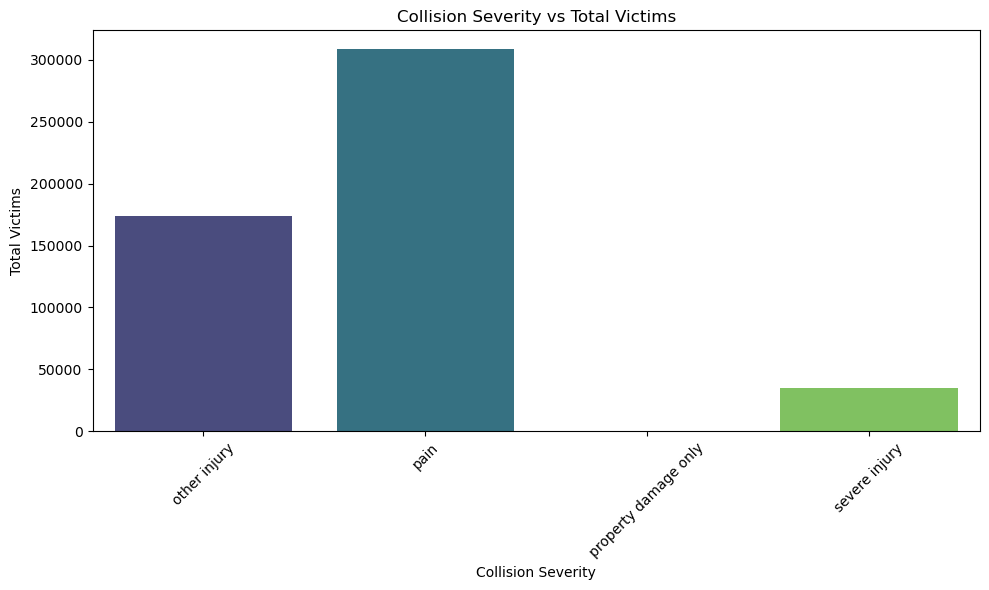

In [56]:
# Bivariate Analysis
# Total victims involved in each collision
severity_vs_victims = (
    cleaned_collisions
    .groupBy("collision_severity")
    .sum("injured_victims", "killed_victims")
    .withColumnRenamed("sum(injured_victims)", "injured_victims")
    .withColumnRenamed("sum(killed_victims)", "killed_victims")
    .toPandas()
)

severity_vs_victims["total_victims"] = (
    severity_vs_victims["injured_victims"] +
    severity_vs_victims["killed_victims"]
)

severity_vs_victims = severity_vs_victims.sort_values("collision_severity")
# Collision Severity vs. Number of Victims

# Convert to Pandas

# Plot
plt.figure(figsize=(10, 6))

sns.barplot(
    data=severity_vs_victims,
    x="collision_severity",
    y="total_victims",
    palette="viridis"
)

plt.title("Collision Severity vs Total Victims")
plt.xlabel("Collision Severity")
plt.ylabel("Total Victims")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

##**3.1.6. Weather Conditions vs Collision Severity.** <font color = red>[5 marks]</font> <br>

Q: Analyze the correlation between weather conditions and collision severity.

<Figure size 1200x600 with 0 Axes>

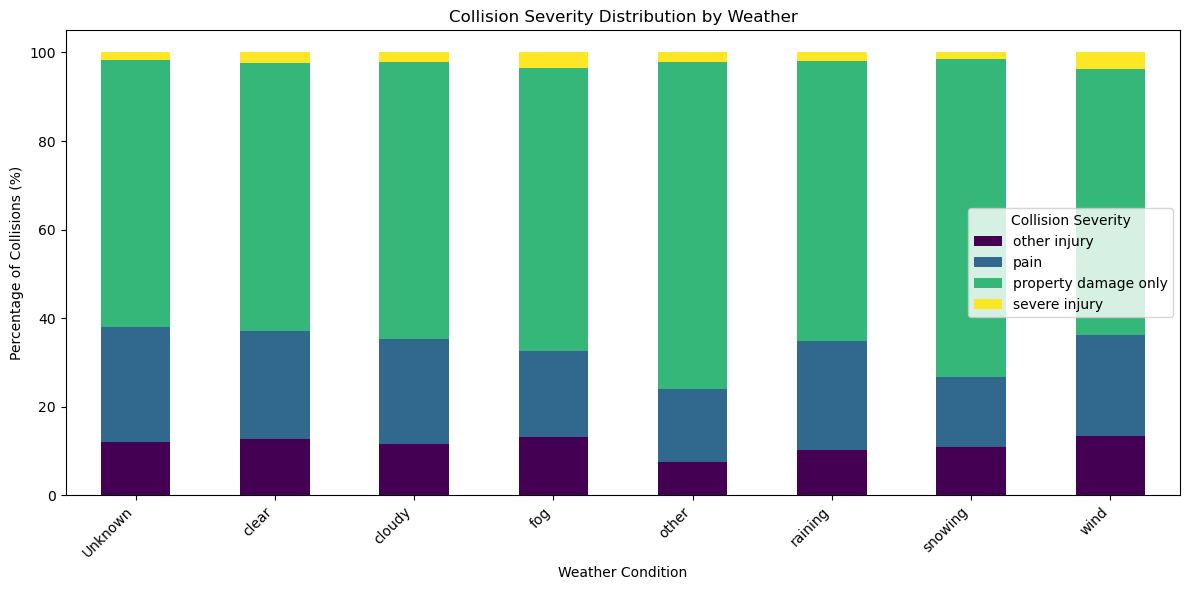

In [57]:
weather_vs_severity = (
    cleaned_collisions
    .groupBy("weather", "collision_severity")
    .count()
    .toPandas()
)

pivot_df = weather_vs_severity.pivot(
    index="weather",
    columns="collision_severity",
    values="count"
).fillna(0)

# Convert each row to percentages
pivot_pct = pivot_df.div(pivot_df.sum(axis=1), axis=0) * 100

plt.figure(figsize=(12, 6))

pivot_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="viridis"
)

plt.title("Collision Severity Distribution by Weather")
plt.xlabel("Weather Condition")
plt.ylabel("Percentage of Collisions (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Collision Severity")
plt.tight_layout()

plt.show()

##**3.1.7. Lighting conditions vs Collision Severity.** <font color = red>[5 marks]</font> <br>

Q:Visualize the impact of lighting conditions on collision severity.

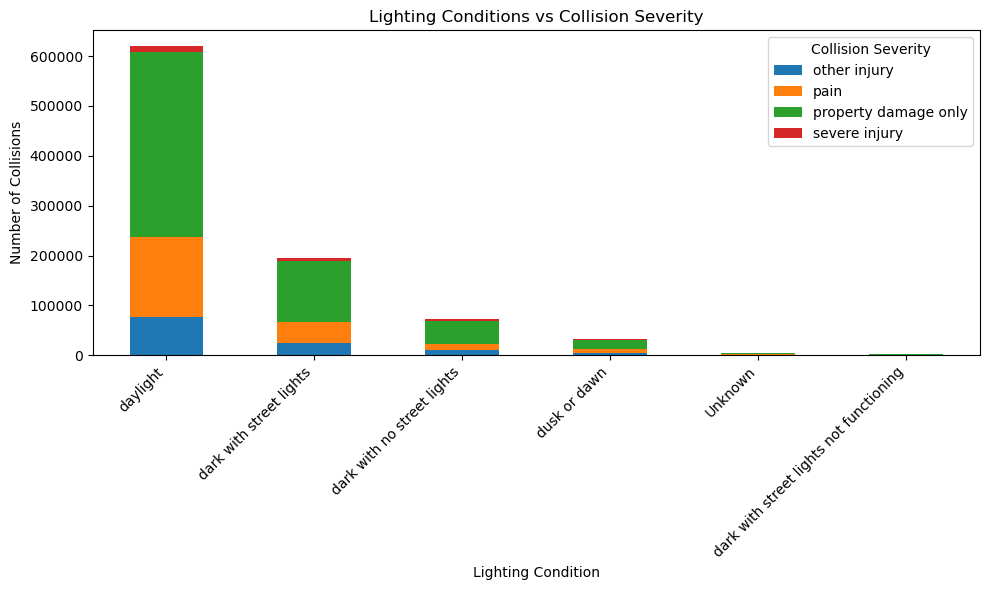

In [58]:

# Convert to Pandas
lighting_severity = (
    cleaned_collisions
    .groupBy("lighting", "collision_severity")
    .count()
    .toPandas()
)

# Pivot data for plotting
lighting_pivot = lighting_severity.pivot(
    index="lighting",
    columns="collision_severity",
    values="count"
).fillna(0)

# Order by total collisions
lighting_pivot = lighting_pivot.loc[
    lighting_pivot.sum(axis=1).sort_values(ascending=False).index
]

# Plot
lighting_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Lighting Conditions vs Collision Severity")
plt.xlabel("Lighting Condition")
plt.ylabel("Number of Collisions")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Collision Severity")
plt.tight_layout()
plt.show()

##**3.1.8. Weekday-Wise Collision Trends.** <font color = red>[7 marks]</font> <br>

Q: Extract and analyze weekday-wise collision trends.

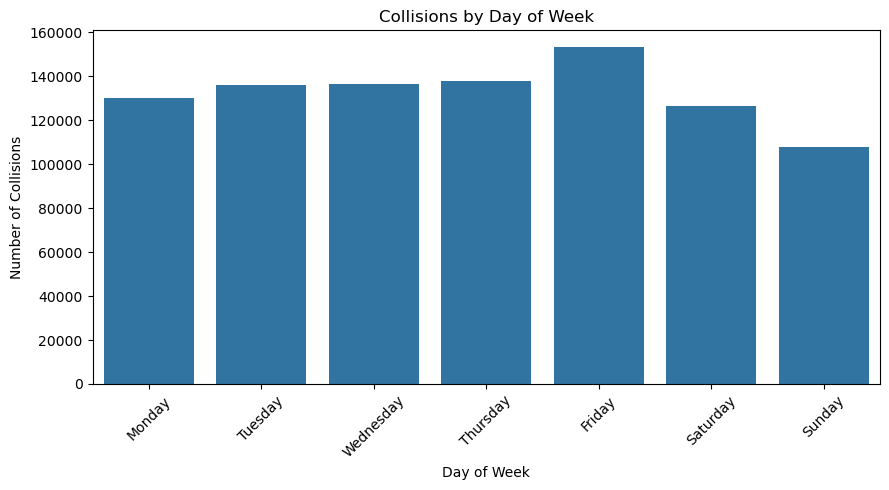

In [59]:
# Extract the weekday


# Extract weekday
weekday_df = (
    cleaned_collisions
    .withColumn("weekday", date_format("collision_date", "EEEE"))
)

# Count collisions by weekday
weekday_counts = (
    weekday_df
    .groupBy("weekday")
    .count()
    .toPandas()
)
# Plot

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_counts["weekday"] = pd.Categorical(
    weekday_counts["weekday"],
    categories=weekday_order,
    ordered=True
)

weekday_counts = weekday_counts.sort_values("weekday")

plt.figure(figsize=(9, 5))
sns.barplot(
    data=weekday_counts,
    x="weekday",
    y="count"
)

plt.title("Collisions by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Collisions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##**3.1.9. Spatial Distribution of Collisions.** <font color = red>[7 marks]</font> <br>

Q: Study spatial distribution of collisions by county.

/tmp/ipykernel_53627/292393265.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 t

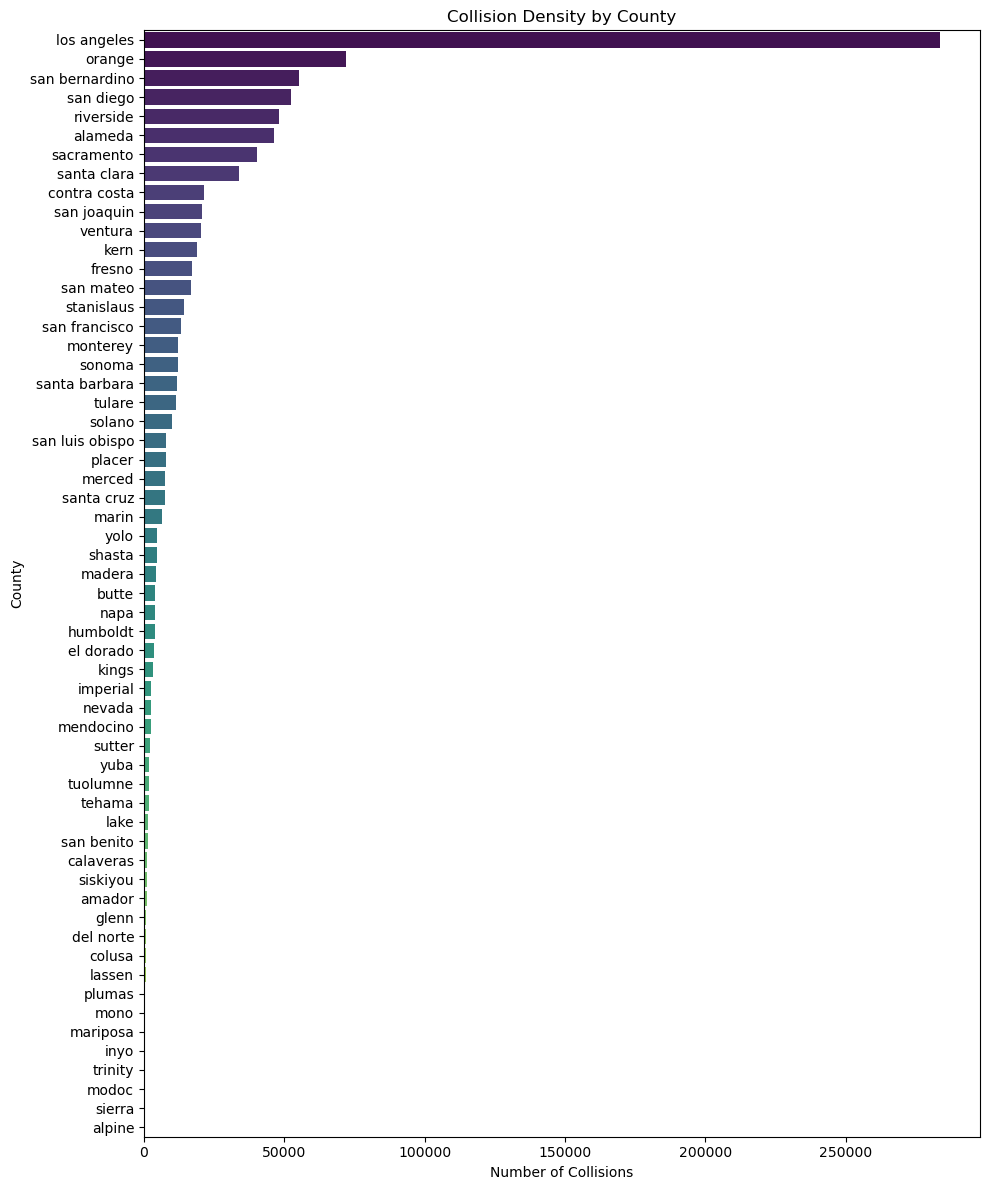

In [60]:
# Collision Density by County

# Convert to Pandas
county_df = (
    cleaned_collisions
    .groupBy("county_location")
    .count()
    .orderBy("count", ascending=False)
    .toPandas()
)

# Plot
plt.figure(figsize=(10, 12))

sns.barplot(
    data=county_df,
    y="county_location",
    x="count",
    palette="viridis"
)

plt.title("Collision Density by County")
plt.xlabel("Number of Collisions")
plt.ylabel("County")
plt.tight_layout()
plt.show()

##**3.1.10. Collision Analysis by Geography.** <font color = red>[6 marks]</font> <br>

Q: Generate a scatter plot to analyze collision locations geographically.

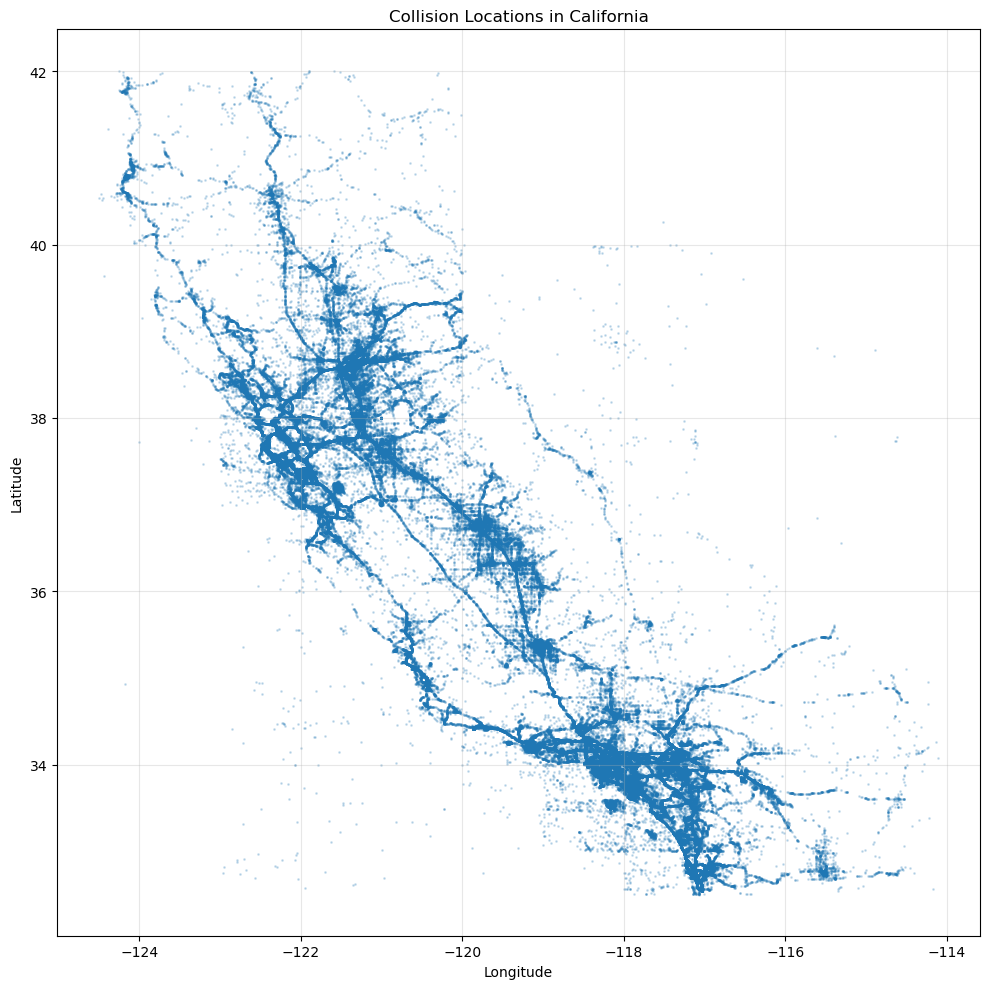

In [61]:
# Scatter Plot of Collision Locations

# Convert PySpark DataFrame to Pandas, handling potential missing values
location_df = (
    cleaned_collisions
    .select("latitude", "longitude")
    .dropna()
    .toPandas()
)
# Convert to numeric (if needed) and handle invalid data


location_df["latitude"] = pd.to_numeric(location_df["latitude"], errors="coerce")
location_df["longitude"] = pd.to_numeric(location_df["longitude"], errors="coerce")

location_df = location_df.dropna()

# Keep only valid California coordinates
location_df = location_df[
    (location_df["latitude"].between(32, 43)) &
    (location_df["longitude"].between(-125, -114))
]

# Plot the scatter plot

plt.figure(figsize=(10, 10))

plt.scatter(
    location_df["longitude"],
    location_df["latitude"],
    s=1,
    alpha=0.2
)

plt.title("Collision Locations in California")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


##**3.1.11. Collision Trends Over Time.** <font color = red>[10 marks]</font> <br>

Extract and analyzing collision trends over time.

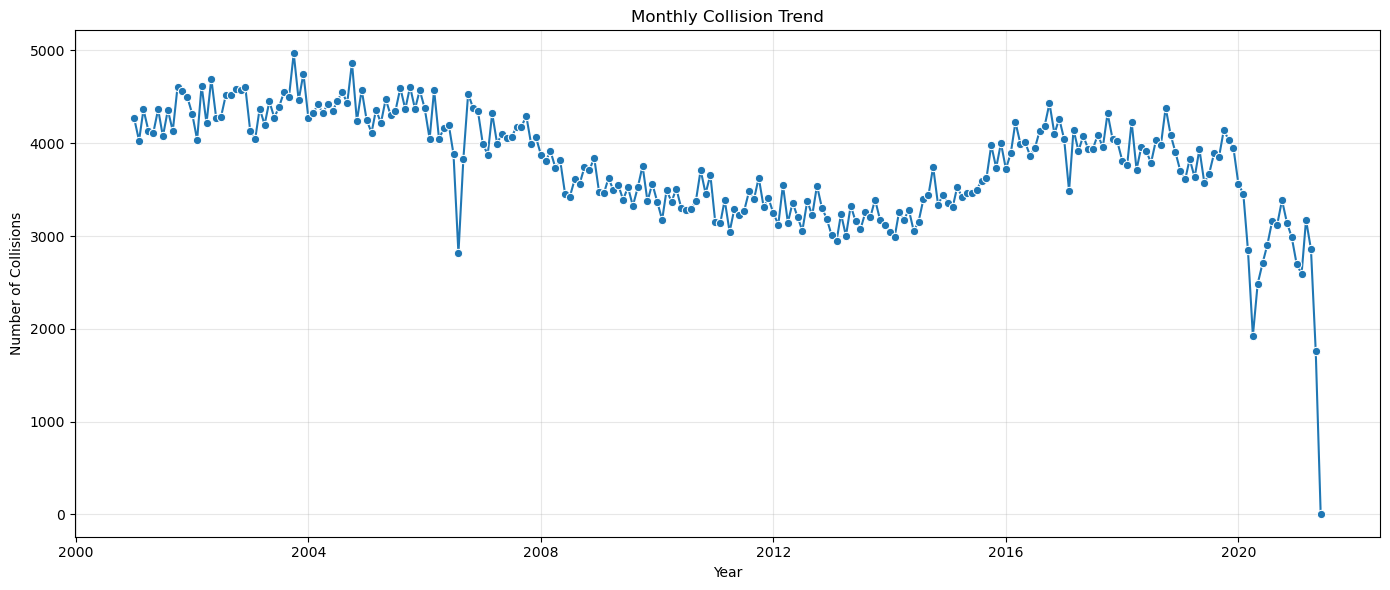

In [62]:
# Extract year and month from collision_date

# Extract year and month from collision_date
monthly_trend = (
    cleaned_collisions
    .withColumn("year", year(col("collision_date")))
    .withColumn("month", month(col("collision_date")))
    .groupBy("year", "month")
    .count()
    .orderBy("year", "month")
    .toPandas()
)
# Plot

monthly_trend["date"] = pd.to_datetime(
    monthly_trend[["year", "month"]].assign(day=1)
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_trend,
    x="date",
    y="count",
    marker="o"
)

plt.title("Monthly Collision Trend")
plt.xlabel("Year")
plt.ylabel("Number of Collisions")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Q: Analyze yearly, monthly and hourly trends in collisions.

/tmp/ipykernel_53627/3448465578.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 

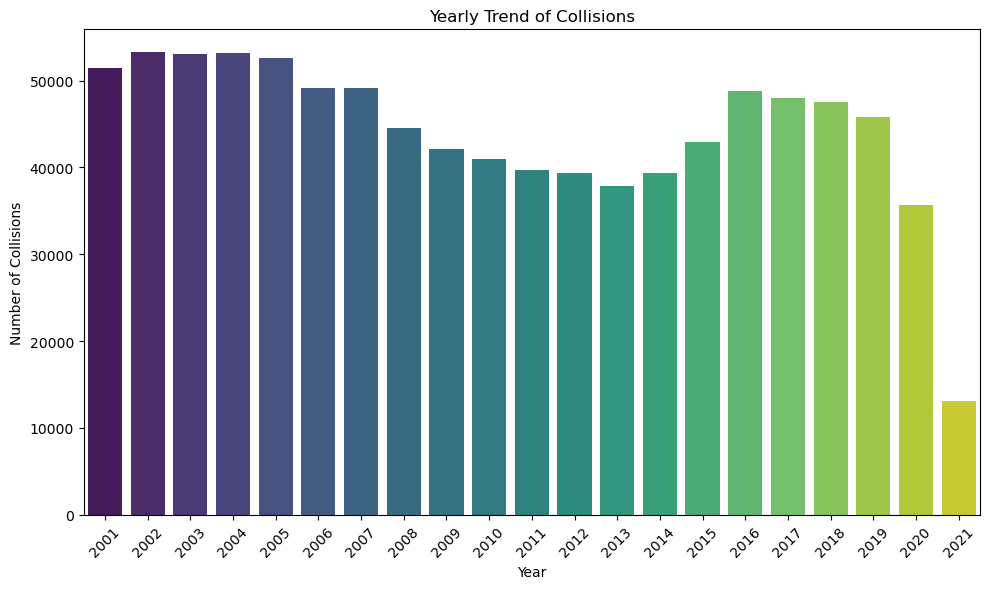

In [63]:
# Yearly Trend of Collisions

# Extract year and count collisions
yearly_trend = (
    cleaned_collisions
    .withColumn("year", year(col("collision_date")))
    .groupBy("year")
    .count()
    .orderBy("year")
    .toPandas()
)
# Plot

plt.figure(figsize=(10, 6))

sns.barplot(
    data=yearly_trend,
    x="year",
    y="count",
    palette="viridis"
)

plt.title("Yearly Trend of Collisions")
plt.xlabel("Year")
plt.ylabel("Number of Collisions")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

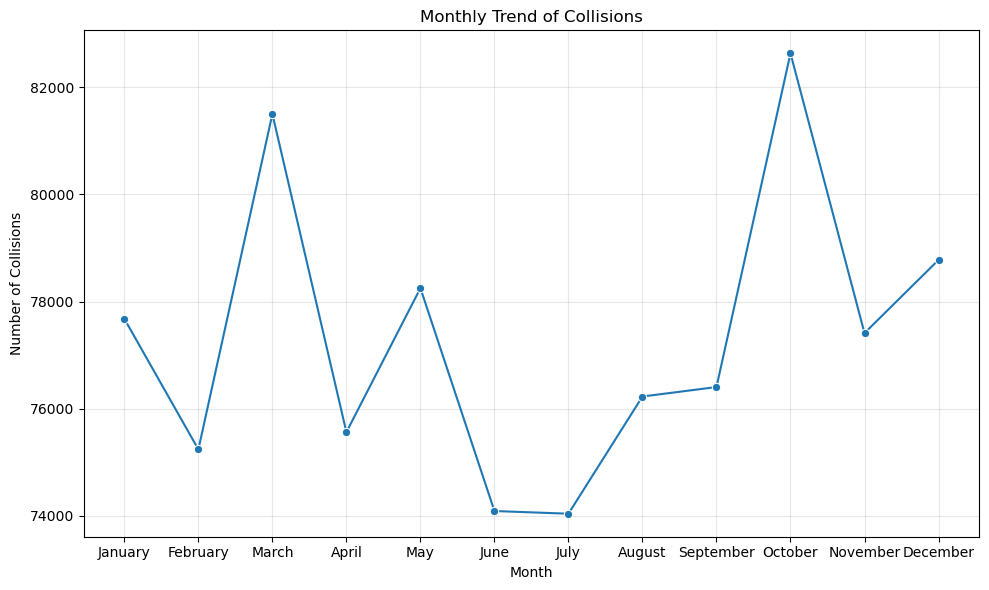

In [64]:
# Monthly Trend of Collisions

# Extract month and count collisions
monthly_trend = (
    cleaned_collisions
    .withColumn("month", month(col("collision_date")))
    .groupBy("month")
    .count()
    .orderBy("month")
    .toPandas()
)


monthly_trend["month_name"] = monthly_trend["month"].apply(
    lambda x: calendar.month_name[x]
)
# Plot
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=monthly_trend,
    x="month_name",
    y="count",
    marker="o"
)

plt.title("Monthly Trend of Collisions")
plt.xlabel("Month")
plt.ylabel("Number of Collisions")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

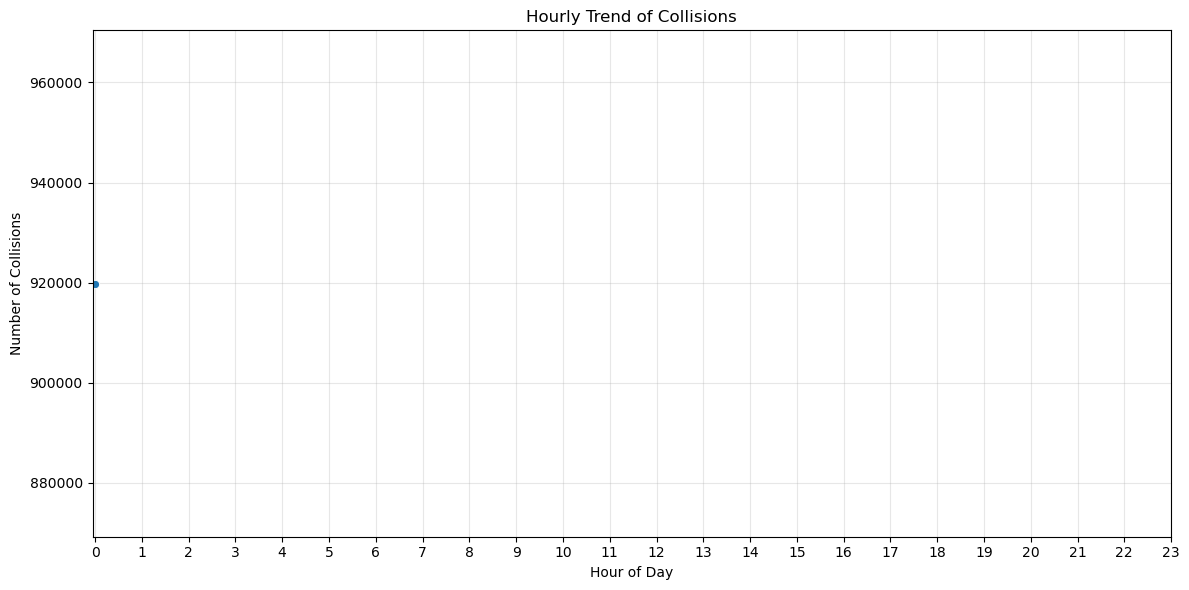

In [65]:
# Hourly Trend of Collisions
hourly_trend = (
    cleaned_collisions
    .withColumn("hour", hour(col("collision_time")))
    .groupBy("hour")
    .count()
    .orderBy("hour")
    .toPandas()
)
# Plot

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hourly_trend,
    x="hour",
    y="count",
    marker="o"
)

plt.title("Hourly Trend of Collisions")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Collisions")

plt.xticks(range(0, 24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#**4. ETL Querying** <font color = red>[35 marks]</font> <br>

## **4.1. Top 5 Counties** <font color = red>[4 marks]</font> <br>

Q: Identify the top 5 counties with the highest number of collisions.

In [66]:
# Query: Identify the top 5 counties with the most collisions
# Query: Identify the top 5 counties with the most collisions

top_5_counties = (
    cleaned_collisions
    .groupBy("county_location")
    .count()
    .orderBy(col("count").desc())
    .limit(5)
)

top_5_counties.show(truncate=False)

+---------------+------+
|county_location|count |
+---------------+------+
|los angeles    |283598|
|orange         |71976 |
|san bernardino |55242 |
|san diego      |52477 |
|riverside      |48041 |
+---------------+------+



## **4.2. Month with Highest Collisions** <font color = red>[5 marks]</font> <br>

Q. Identify the month with the highest number of collisions.

In [67]:
# Query: Find the month with the highest number of collisions
# Query: Find the month with the highest number of collisions

monthly_collisions = (
    cleaned_collisions
    .withColumn("month", month("collision_date"))
    .groupBy("month")
    .count()
    .orderBy(col("count").desc())
)

monthly_collisions.show()

+-----+-----+
|month|count|
+-----+-----+
|   10|82634|
|    3|81502|
|   12|78777|
|    5|78250|
|    1|77678|
|   11|77411|
|    9|76404|
|    8|76227|
|    4|75562|
|    2|75239|
|    6|74089|
|    7|74039|
+-----+-----+



## **4.3. Weather Conditions with Highest Collisions.** <font color = red>[5 marks]</font> <br>

Q. Determine the most common weather condition during collisions.

In [68]:
# Query: Find the most common weather condition during collisions

weather_collisions = (
    cleaned_collisions
    .groupBy("weather")
    .count()
    .orderBy(col("count").desc())
)

weather_collisions.show(truncate=False)

+-------+------+
|weather|count |
+-------+------+
|clear  |763768|
|cloudy |120800|
|raining|32079 |
|Unknown|4604  |
|fog    |3844  |
|snowing|1271  |
|other  |1063  |
|wind   |383   |
+-------+------+



## **4.4. Fatal Collisions.** <font color = red>[5 marks]</font> <br>

Q. Calculate the percentage of collisions that resulted in fatalities.

In [69]:
# Query: Determine the percentage of collisions that resulted in fatalities
total_collisions = cleaned_collisions.count()

fatal_collisions = (
    cleaned_collisions
    .filter(col("killed_victims") > 0)
    .count()
)

fatal_percentage = (fatal_collisions / total_collisions) * 100

print(f"Total Collisions      : {total_collisions}")
print(f"Fatal Collisions      : {fatal_collisions}")
print(f"Fatal Collision Rate  : {fatal_percentage:.2f}%")

Total Collisions      : 927812
Fatal Collisions      : 0
Fatal Collision Rate  : 0.00%


## **4.5. Dangerous Time for Collisions.** <font color = red>[5 marks]</font> <br>

Q. Find the most dangerous time of day for collisions.

In [70]:
# Query: Find the most dangerous time of day for collisions

cleaned_collisions.select("collision_time") \
    .distinct() \
    .orderBy("collision_time") \
    .show(20, truncate=False)

+--------------+
|collision_time|
+--------------+
|NULL          |
|2026-07-13    |
+--------------+



## **4.6. Road Surface Conditions.** <font color = red>[5 marks]</font> <br>

Q. Identify the top 5 road surface conditions with the highest collision frequency.

In [71]:
# Query: List the top 5 road types with the highest collision frequency

road_conditions = (
    cleaned_collisions
    .groupBy("road_condition")
    .count()
    .orderBy(col("count").desc())
    .limit(5)
)

road_conditions.show(truncate=False)

+--------------+------+
|road_condition|count |
+--------------+------+
|normal        |891951|
|construction  |14844 |
|Unknown       |7879  |
|obstruction   |3544  |
|other         |3420  |
+--------------+------+



## **4.7. Lighting Conditions.** <font color = red>[5 marks]</font> <br>

Q. Analyze lighting conditions that contribute to the highest number of collisions.

In [72]:
# Query: Find the top 3 lighting conditions that lead to the most collisions
lighting_conditions = (
    cleaned_collisions
    .groupBy("lighting")
    .count()
    .orderBy(col("count").desc())
)

lighting_conditions.show(truncate=False)

+---------------------------------------+------+
|lighting                               |count |
+---------------------------------------+------+
|daylight                               |620462|
|dark with street lights                |195708|
|dark with no street lights             |72259 |
|dusk or dawn                           |32338 |
|Unknown                                |5285  |
|dark with street lights not functioning|1760  |
+---------------------------------------+------+



#5. Conclusion <font color = red>[10 marks]</font> <br>

Write your conclusion.

In this project, I developed an ETL pipeline to clean and prepare the California traffic collision dataset for analysis. The cleaning process included handling missing values, removing invalid records, correcting inconsistent values, renaming and reordering columns, and converting data into a format suitable for querying and visualization.

The analysis revealed several useful insights. 
- Los Angeles County recorded the highest number of collisions, followed by Orange, San Bernardino, San Diego, and Riverside counties.
- October had the highest number of reported collisions, while July recorded the lowest among all months.
- Clear weather accounted for the majority of collisions, followed by cloudy and rainy conditions.
- Normal road surface conditions and daylight were associated with the highest number of reported collisions, mainly because these are the conditions under which most vehicles are on the road.
- The victim age distribution became much more realistic after removing invalid age values, with most victims belonging to the young and middle-aged population.
- Most collisions resulted in property damage only, while severe injury collisions represented only a small proportion of the total cases.

During the ETL process, several data quality issues were identified. Invalid age values such as 999 years and unrealistic ages above 120 years were removed from the victims and parties datasets. Missing categorical values were replaced with **"Unknown"**, and inconsistent column names were standardized to improve readability. One important limitation of the dataset was the collision time field. Although the dataset contained a `collision_time` column, it did not contain valid hour-level information, making it impossible to determine the most dangerous time of day for collisions. Rather than producing misleading results, this limitation was documented in the report.

Another observation was that no fatal collisions were identified using the `killed_victims` field after the cleaning process. This indicates either that fatalities are not represented in the provided dataset or that the field does not contain complete information for this analysis. This limitation should be considered when interpreting the results.

Overall, the ETL pipeline produced a clean and consistent dataset that can be used for further analysis and visualization. More importantly, the project demonstrated that careful data cleaning is essential before drawing conclusions, as inaccurate or incomplete data can significantly affect the reliability of analytical results.

#6. Visualization Integration using Tableau/ PowerBI <font color = red>[Optional]</font> <br>